# Chapter 11 — Novelty and Outlier Detection

**Reference:** *scikit-learn Cookbook, Third Edition* — John Sukup

This notebook demonstrates Isolation Forest, Local Outlier Factor, and One-Class SVM.

## 1. Theory
**Outlier detection** finds unusual observations within a dataset. **Novelty detection** learns normal patterns from training data and flags unusual future observations. Isolation Forest uses random partitions, LOF compares local density, and One-Class SVM learns a boundary around normal data. Common predictions are `1` for inliers and `-1` for outliers.

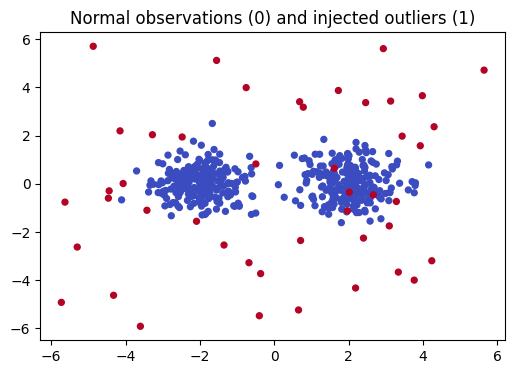

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RANDOM_STATE = 42

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
rng=np.random.default_rng(RANDOM_STATE)
X_normal,_=make_blobs(n_samples=450,centers=[(-2,0),(2,0)],cluster_std=[.65,.7],random_state=RANDOM_STATE)
X_out=rng.uniform(-6,6,size=(45,2))
X=np.vstack([X_normal,X_out]); y_true=np.r_[np.zeros(len(X_normal),int),np.ones(len(X_out),int)]
scaler=StandardScaler().fit(X_normal); X_scaled=scaler.transform(X)
plt.figure(figsize=(6,4)); plt.scatter(X[:,0],X[:,1],c=y_true,s=18,cmap="coolwarm")
plt.title("Normal observations (0) and injected outliers (1)"); plt.show()


## 2. Isolation Forest

              precision    recall  f1-score   support

      Inlier       0.98      0.98      0.98       450
     Outlier       0.82      0.82      0.82        45

    accuracy                           0.97       495
   macro avg       0.90      0.90      0.90       495
weighted avg       0.97      0.97      0.97       495

Confusion matrix:
 [[442   8]
 [  8  37]]
ROC AUC: 0.948


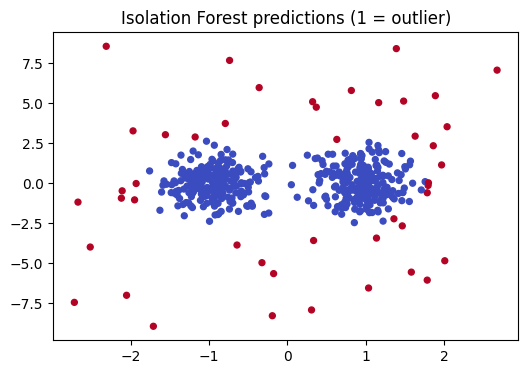

In [2]:

iso=IsolationForest(contamination=len(X_out)/len(X),random_state=RANDOM_STATE).fit(X_scaled)
iso_pred=(iso.predict(X_scaled)==-1).astype(int)
print(classification_report(y_true,iso_pred,target_names=["Inlier","Outlier"],zero_division=0))
print("Confusion matrix:\n",confusion_matrix(y_true,iso_pred))
print("ROC AUC:",round(roc_auc_score(y_true,-iso.score_samples(X_scaled)),3))
plt.figure(figsize=(6,4)); plt.scatter(X_scaled[:,0],X_scaled[:,1],c=iso_pred,s=18,cmap="coolwarm")
plt.title("Isolation Forest predictions (1 = outlier)"); plt.show()


## 3. Local Outlier Factor

In [3]:

lof=LocalOutlierFactor(n_neighbors=20,contamination=len(X_out)/len(X))
lof_pred=(lof.fit_predict(X_scaled)==-1).astype(int)
print(classification_report(y_true,lof_pred,target_names=["Inlier","Outlier"],zero_division=0))
print("LOF confusion matrix:\n",confusion_matrix(y_true,lof_pred))


              precision    recall  f1-score   support

      Inlier       0.98      0.98      0.98       450
     Outlier       0.80      0.80      0.80        45

    accuracy                           0.96       495
   macro avg       0.89      0.89      0.89       495
weighted avg       0.96      0.96      0.96       495

LOF confusion matrix:
 [[441   9]
 [  9  36]]


## 4. Novelty detection with One-Class SVM

              precision    recall  f1-score   support

      Normal       0.94      0.90      0.92        80
       Novel       0.83      0.89      0.86        45

    accuracy                           0.90       125
   macro avg       0.88      0.89      0.89       125
weighted avg       0.90      0.90      0.90       125

One-Class SVM ROC AUC: 0.952


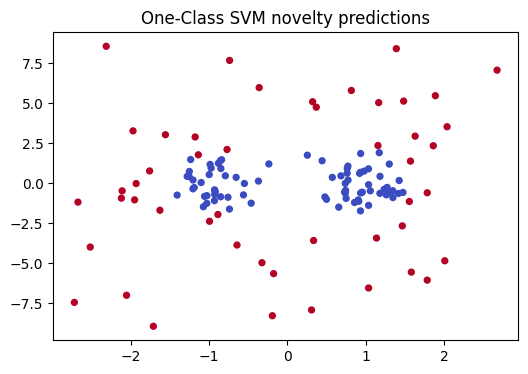

In [4]:

X_future=np.vstack([X_normal[:80],X_out])
y_future=np.r_[np.zeros(80,int),np.ones(len(X_out),int)]
oc=OneClassSVM(kernel="rbf",gamma="scale",nu=.1).fit(scaler.transform(X_normal))
X_future_scaled=scaler.transform(X_future)
oc_pred=(oc.predict(X_future_scaled)==-1).astype(int)
scores=-oc.decision_function(X_future_scaled).ravel()
print(classification_report(y_future,oc_pred,target_names=["Normal","Novel"],zero_division=0))
print("One-Class SVM ROC AUC:",round(roc_auc_score(y_future,scores),3))
plt.figure(figsize=(6,4)); plt.scatter(X_future_scaled[:,0],X_future_scaled[:,1],c=oc_pred,s=18,cmap="coolwarm")
plt.title("One-Class SVM novelty predictions"); plt.show()


## Exercises
1. Change the contamination estimate for Isolation Forest and LOF.
2. Change LOF's `n_neighbors` and compare precision and recall.
3. Change One-Class SVM's `nu`.
4. Explain outlier detection versus novelty detection.

## Summary
Anomaly labels are often unavailable in real work. Where labels exist, evaluate precision, recall, F1, confusion matrices, and score-based ROC AUC. Treat detections as signals to investigate, not proof of an error.